In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve)

In [3]:
# Load dataset
df = pd.read_csv("/content/diabetes_012_health_indicators_BRFSS2015.csv")

In [4]:
print("First five rows:")
print(df.head())

print("\nDataset shape:")
print(df.shape)

print("\nDataset information:")
df.info()

print("\nSummary statistics:")
print(df.describe())

print("\nMissing values:")
print(df.isnull().sum())

First five rows:
   Diabetes_012  HighBP  HighChol  CholCheck   BMI  Smoker  Stroke  \
0           0.0     1.0       1.0        1.0  40.0     1.0     0.0   
1           0.0     0.0       0.0        0.0  25.0     1.0     0.0   
2           0.0     1.0       1.0        1.0  28.0     0.0     0.0   
3           0.0     1.0       0.0        1.0  27.0     0.0     0.0   
4           0.0     1.0       1.0        1.0  24.0     0.0     0.0   

   HeartDiseaseorAttack  PhysActivity  Fruits  ...  AnyHealthcare  \
0                   0.0           0.0     0.0  ...            1.0   
1                   0.0           1.0     0.0  ...            0.0   
2                   0.0           0.0     1.0  ...            1.0   
3                   0.0           1.0     1.0  ...            1.0   
4                   0.0           1.0     1.0  ...            1.0   

   NoDocbcCost  GenHlth  MentHlth  PhysHlth  DiffWalk  Sex   Age  Education  \
0          0.0      5.0      18.0      15.0       1.0  0.0   9.0    

In [6]:
print(df.columns)

Index(['Diabetes_012', 'HighBP', 'HighChol', 'CholCheck', 'BMI', 'Smoker',
       'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies',
       'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth',
       'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age', 'Education',
       'Income'],
      dtype='object')


In [21]:
# Check duplicate records
print("Duplicate rows:", df.duplicated().sum())

# Remove duplicate records if any
df = df.drop_duplicates()

Duplicate rows: 0


In [32]:
# Check target class distribution
print(df["Diabetes_012"].value_counts())

# Convert target into binary classification
# 0 = No diabetes
# 1 = Prediabetes or diabetes

df["Diabetes"] = df["Diabetes_012"].apply(
    lambda x: 0 if x == 0 else 1
)

# Separate features and target
X = df.drop(["Diabetes_012", "Diabetes"], axis=1)
y = df["Diabetes"]

# Split dataset into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Diabetes_012
0.0    190055
2.0     35097
1.0      4629
Name: count, dtype: int64
Training data: (183824, 21)
Testing data: (45957, 21)


In [38]:
# Create Logistic Regression model
model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

# Train the model
model.fit(X_train, y_train)

print("Model trained successfully")

Model trained successfully


In [39]:
# Make predictions
y_pred = model.predict(X_test)

# Calculate prediction probabilities
y_prob = model.predict_proba(X_test)[:, 1]

# Evaluation metrics
print("Accuracy:", accuracy_score(y_test, y_pred))

print("Precision:", precision_score(
    y_test, y_pred, zero_division=0
))

print("Recall:", recall_score(
    y_test, y_pred, zero_division=0
))

print("F1 Score:", f1_score(
    y_test, y_pred, zero_division=0
))

print("ROC-AUC:", roc_auc_score(y_test, y_prob))

# Classification report
print("\nClassification Report:")
print(classification_report(
    y_test, y_pred, zero_division=0
))

Accuracy: 0.7194769023217356
Precision: 0.35317860746720486
Recall: 0.748898678414097
F1 Score: 0.47999354630525976
ROC-AUC: 0.8053198132191969

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.71      0.81     38012
           1       0.35      0.75      0.48      7945

    accuracy                           0.72     45957
   macro avg       0.64      0.73      0.64     45957
weighted avg       0.83      0.72      0.75     45957



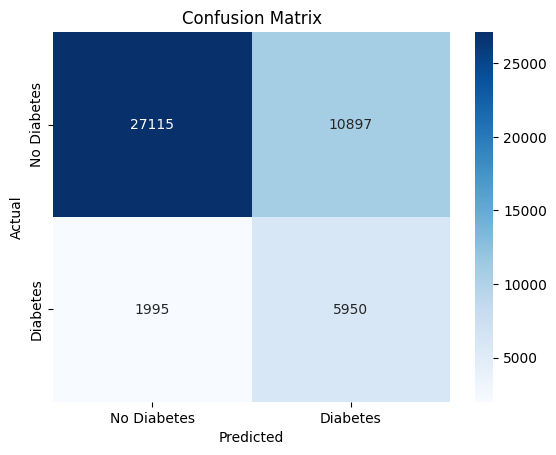

In [40]:
# Calculate confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Display confusion matrix
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Diabetes", "Diabetes"],
    yticklabels=["No Diabetes", "Diabetes"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

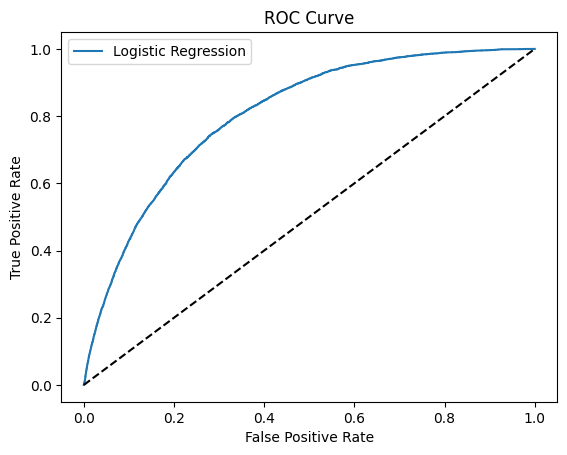

In [41]:
# Calculate ROC curve
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

# Plot ROC curve
plt.plot(fpr, tpr, label="Logistic Regression")
plt.plot([0, 1], [0, 1], "k--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

Feature Coefficients:
                 Feature  Coefficient
13               GenHlth     0.550437
3                    BMI     0.465994
18                   Age     0.449312
0                 HighBP     0.327805
1               HighChol     0.288605
2              CholCheck     0.238661
17                   Sex     0.131099
6   HeartDiseaseorAttack     0.057164
16              DiffWalk     0.034198
5                 Stroke     0.027665
12           NoDocbcCost     0.022476
11         AnyHealthcare     0.015962
9                Veggies    -0.003899
7           PhysActivity    -0.004525
8                 Fruits    -0.011372
4                 Smoker    -0.013488
14              MentHlth    -0.015957
19             Education    -0.028986
15              PhysHlth    -0.058887
20                Income    -0.105823
10     HvyAlcoholConsump    -0.168117


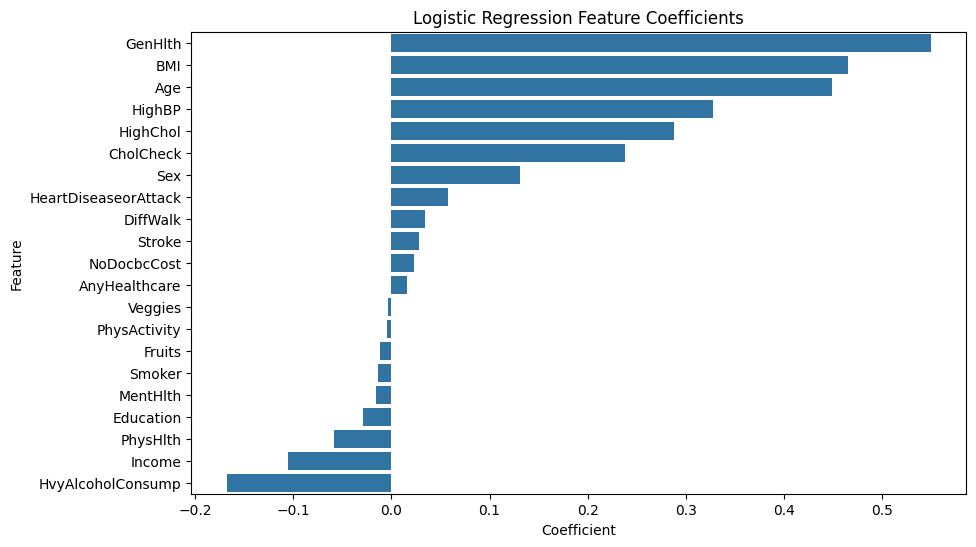

In [42]:
# Get feature names and coefficients
features = X.columns
coefficients = model.named_steps["classifier"].coef_[0]

# Create coefficient table
coef_table = pd.DataFrame({
    "Feature": features,
    "Coefficient": coefficients
})

# Sort coefficients
coef_table = coef_table.sort_values(
    by="Coefficient", ascending=False
)

print("Feature Coefficients:")
print(coef_table)

# Plot coefficients
plt.figure(figsize=(10, 6))

sns.barplot(
    data=coef_table,
    x="Coefficient",
    y="Feature"
)

plt.title("Logistic Regression Feature Coefficients")
plt.show()

In [43]:
# Take one sample from test data
new_person = X_test.iloc[[0]]

# Predict diabetes status
prediction = model.predict(new_person)

# Display result
if prediction[0] == 0:
    print("Prediction: No Diabetes")
else:
    print("Prediction: Diabetes")

Prediction: Diabetes


## **Conclusion**

The Logistic Regression model was developed to predict diabetes status using health indicators from the BRFSS 2015 dataset. The dataset was preprocessed, and the model was trained and evaluated using accuracy, precision, recall, F1-score, ROC-AUC, and a confusion matrix. The feature coefficients were also examined to understand the influence of different health indicators on the predictions.